In [9]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

#downsample: bool=False를 통해 필요할 때만 True로 켰다 껐다 가능.
def preprocess_telco(csv_path: str, downsample: bool=False):
    """
    Telco-Customer-Churn 데이터 전체 전처리 파이프라인
    ------------------------------------------------
    1) CSV 로드 + TotalCharges 숫자 변환
    # 결측 행 제거: 대체 없이 다 떨궈버림.
    2) 이진 특성: Yes/No → 1/0, Male/Female → 0/1
    3) 3단계 특성(Yes/No/No service) → 1/0
    4) 다중 범주(InternetService·Contract·PaymentMethod) → 원-핫
    5) 파생 변수: HasInternet, AvgCharges
    6) 수치형(StandardScaler) 스케일링
    7) 다운샘플링 진행
    8) customerID 제거 → X, y 반환
    """
    # ─────────────────────────────────── 1. 로드 & 기본 정제
    df = pd.read_csv(csv_path, encoding="utf-8")

    df["TotalCharges"] = pd.to_numeric(
        df["TotalCharges"].replace(" ", np.nan), errors="coerce"
    )
    df = df.dropna(subset=["TotalCharges"]).reset_index(drop=True)

    # ─────────────────────────────────── 2. 이진 특성 0/1 매핑
    binary_map = {"Yes": 1, "No": 0}
    bin_cols = ["Partner", "Dependents", "PhoneService",
                "PaperlessBilling", "Churn"]
    df[bin_cols] = df[bin_cols].replace(binary_map)
    df["gender"] = df["gender"].map({"Male": 0, "Female": 1})
    df["SeniorCitizen"] = df["SeniorCitizen"].astype(int)

    # ─────────────────────────────────── 3. 3단계 서비스 특성 0/1
    tri_cols = [
        "MultipleLines", "OnlineSecurity", "OnlineBackup",
        "DeviceProtection", "TechSupport",
        "StreamingTV", "StreamingMovies"
    ]
    df[tri_cols] = df[tri_cols].replace(
        {"Yes": 1, "No": 0,
         "No phone service": 0, "No internet service": 0}
    )

    # ─────────────────────────────────── 4. 다중 범주 원-핫
    multi_cols = ["InternetService", "Contract", "PaymentMethod"]
    df = pd.get_dummies(df, columns=multi_cols, drop_first=True)

    # ─────────────────────────────────── 5. 파생 변수
    df["HasInternet"] = (
        df.get("InternetService_Fiber optic", 0)
        | df.get("InternetService_DSL", 0)
    ).astype(int)

    df["AvgCharges"] = df["TotalCharges"] / df["tenure"].replace(0, np.nan)

    # ─────────────────────────────────── 6. 스케일링
    num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "AvgCharges"]
    scaler = StandardScaler()
    df[num_cols] = scaler.fit_transform(df[num_cols])
    # ─────────────────────────────────── 7. 다운샘플링
    if downsample:
      df_major = df[df.Churn == 0] #탈퇴하지 않은 고객(다수 클래스) 저장
      df_minor = df[df.Churn == 1] #탈퇴한 고객(소수 클래스) 저장
      df_major_down = df_major.sample(n=len(df_minor), random_state=42)
      #df_minor기준으로 df_major 숫자 맞추기
      df = pd.concat([df_major_down, df_minor]).sample(frac=1, random_state=42).reset_index(drop=True)

    # ─────────────────────────────────── 8. 정리 & 반환
    df = df.drop(columns=["customerID"]) #고객 고유 ID는 예측에 필요없는 정보이므로 제거.
    X = df.drop(columns=["Churn"])
    y = df["Churn"]

    return X, y, df

# 밑에 csv_path만 바꾸기

In [11]:
# ── 사용 예시 ──────────────────────────────────────────────
csv_path = "C:/Users/sj/Downloads/archive/WA_Fn-UseC_-Telco-Customer-Churn.csv"

X, y, processed_df = preprocess_telco(csv_path, downsample=True)

print("✅ X shape:", X.shape)
print("✅ y value counts:\n", y.value_counts())


✅ X shape: (3738, 25)
✅ y value counts:
 Churn
0    1869
1    1869
Name: count, dtype: int64


C:\Users\sj\AppData\Local\Temp\ipykernel_21596\333484438.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[bin_cols] = df[bin_cols].replace(binary_map)
C:\Users\sj\AppData\Local\Temp\ipykernel_21596\333484438.py:42: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[tri_cols] = df[tri_cols].replace(


#라이브러리

In [13]:
#라이브러리
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
import optuna

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from sklearn.linear_model import LogisticRegression
import lightgbm as lgb

#모델별 공통

In [16]:
# ────────────────────────────────────────────────
# 1. 데이터 전처리
# ────────────────────────────────────────────────
# ── 사용 예시 ──────────────────────────────────────────────
csv_path = 'C:/Users/sj/Downloads/archive/WA_Fn-UseC_-Telco-Customer-Churn.csv'

X, y, processed_df = preprocess_telco(csv_path, downsample=True)

print("✅ X shape:", X.shape)
print("✅ y value counts:\n", y.value_counts())

# ────────────────────────────────────────────────
# 2. train / test split
# ────────────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

✅ X shape: (3738, 25)
✅ y value counts:
 Churn
0    1869
1    1869
Name: count, dtype: int64


#랜덤포레스트 코드

Fitting 5 folds for each of 16 candidates, totalling 80 fits
✅ Best Params: {'class_weight': 'balanced', 'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 100}
Accuracy : 0.7620
Precision: 0.7526
Recall   : 0.7807
F1-score : 0.7664
ROC AUC  : 0.8455


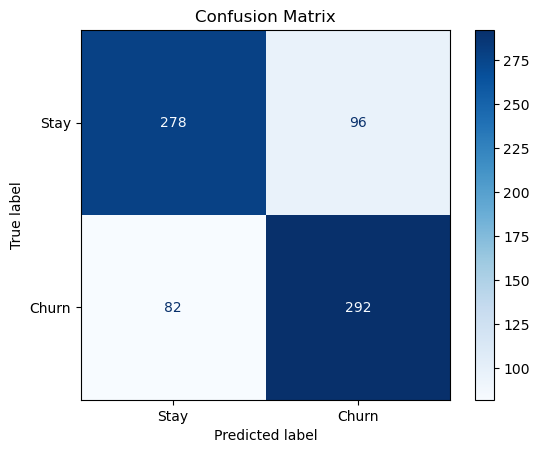


5-fold CV AUC: 0.8389 ± 0.0153


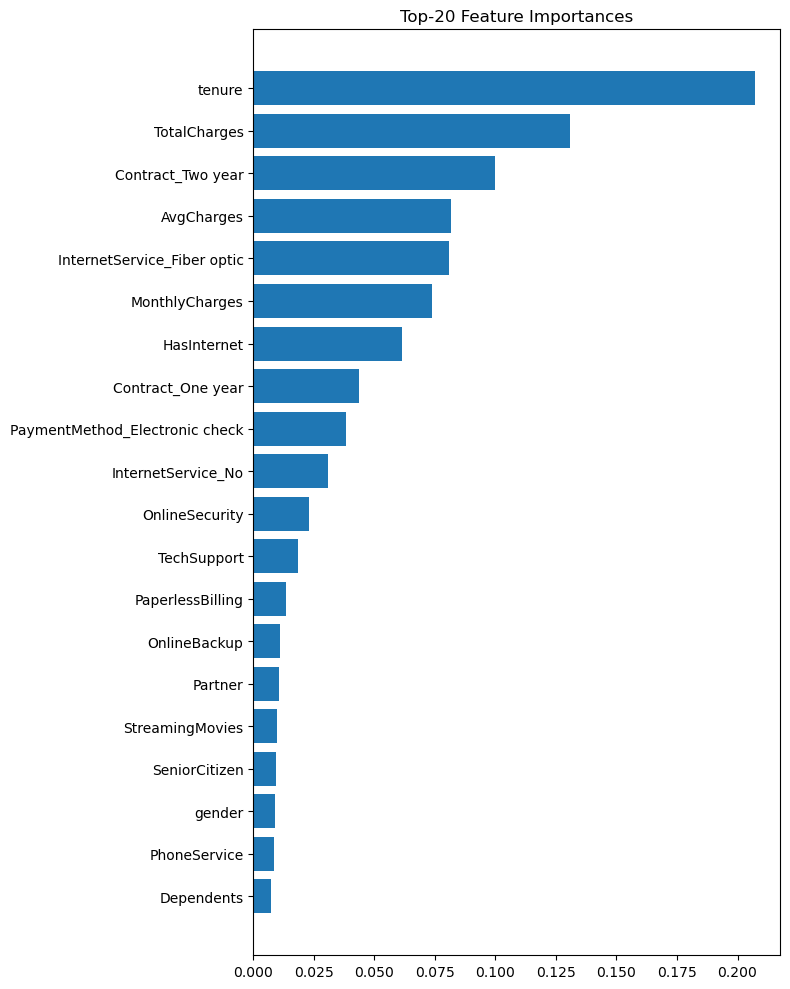

In [33]:
# ────────────────────────────────────────────────
# 랜덤포레스트 모델링 (그리드서치 적용)
# ────────────────────────────────────────────────
hyper_params = {
    'n_estimators': [100, 300],
    'max_depth': [8, 10],
    'min_samples_split': [5, 10],
    'min_samples_leaf': [2, 4],
    'max_features': ['sqrt'],
    'class_weight': ['balanced']
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf_grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid=hyper_params,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# ────────────────────────────────────────────────
# 모델 학습
# ────────────────────────────────────────────────
rf_grid_search.fit(X_train, y_train)
rf_clf = rf_grid_search.best_estimator_
y_pred = rf_clf.predict(X_test)
y_prob = rf_clf.predict_proba(X_test)[:, 1]

# ────────────────────────────────────────────────
# 성능지표
# ────────────────────────────────────────────────
rf_grid_acc  = accuracy_score(y_test, y_pred)
rf_grid_prec = precision_score(y_test, y_pred, zero_division=0)
rf_grid_rec  = recall_score(y_test, y_pred)
rf_grid_f1   = f1_score(y_test, y_pred)
rf_grid_auc  = roc_auc_score(y_test, y_prob)

print(f"✅ Best Params: {rf_grid_search.best_params_}")
print(f"Accuracy : {rf_grid_acc:.4f}")
print(f"Precision: {rf_grid_prec:.4f}")
print(f"Recall   : {rf_grid_rec:.4f}")
print(f"F1-score : {rf_grid_f1:.4f}")
print(f"ROC AUC  : {rf_grid_auc:.4f}")

# ────────────────────────────────────────────────
# 혼동 행렬
# ────────────────────────────────────────────────
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Stay", "Churn"]).plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

# ────────────────────────────────────────────────
# 5-fold CV (AUC)
# ────────────────────────────────────────────────
#cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) 3번에서 사용한 cv 사용.
cv_auc = cross_val_score(rf_clf, X, y, cv=cv, scoring="roc_auc", n_jobs=-1)
print(f"\n5-fold CV AUC: {cv_auc.mean():.4f} ± {cv_auc.std():.4f}")

# ────────────────────────────────────────────────
# 피처 중요도 시각화
# ────────────────────────────────────────────────
importances = rf_clf.feature_importances_
indices = np.argsort(importances)[::-1][:20]
features = X.columns[indices]

plt.figure(figsize=(8, 10))
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), features)
plt.gca().invert_yaxis()
plt.title("Top-20 Feature Importances")
plt.tight_layout()
plt.show()


[I 2025-05-30 18:16:16,064] A new study created in memory with name: no-name-9231039d-949f-4fa4-8047-e5338c3c9cc7


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2025-05-30 18:16:16,643] Trial 0 finished with value: 0.8397646558763325 and parameters: {'n_estimators': 421, 'max_depth': 20, 'min_samples_split': 4, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'class_weight': 'balanced'}. Best is trial 0 with value: 0.8397646558763325.
[I 2025-05-30 18:16:17,201] Trial 1 finished with value: 0.8409480878289951 and parameters: {'n_estimators': 418, 'max_depth': 10, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'class_weight': 'balanced'}. Best is trial 1 with value: 0.8409480878289951.
[I 2025-05-30 18:16:17,757] Trial 2 finished with value: 0.8387691412847731 and parameters: {'n_estimators': 307, 'max_depth': 17, 'min_samples_split': 9, 'min_samples_leaf': 3, 'max_features': 'log2', 'class_weight': 'balanced_subsample'}. Best is trial 1 with value: 0.8409480878289951.
[I 2025-05-30 18:16:18,211] Trial 3 finished with value: 0.8366259885236182 and parameters: {'n_estimators': 238, 'max_depth': 15, 'min_samples_split': 

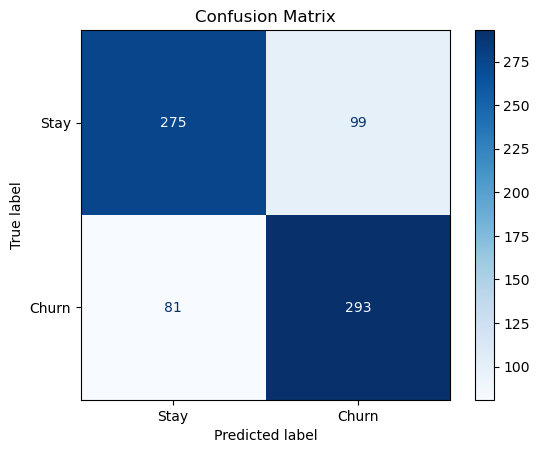


5-fold CV AUC: 0.8389 ± 0.0153


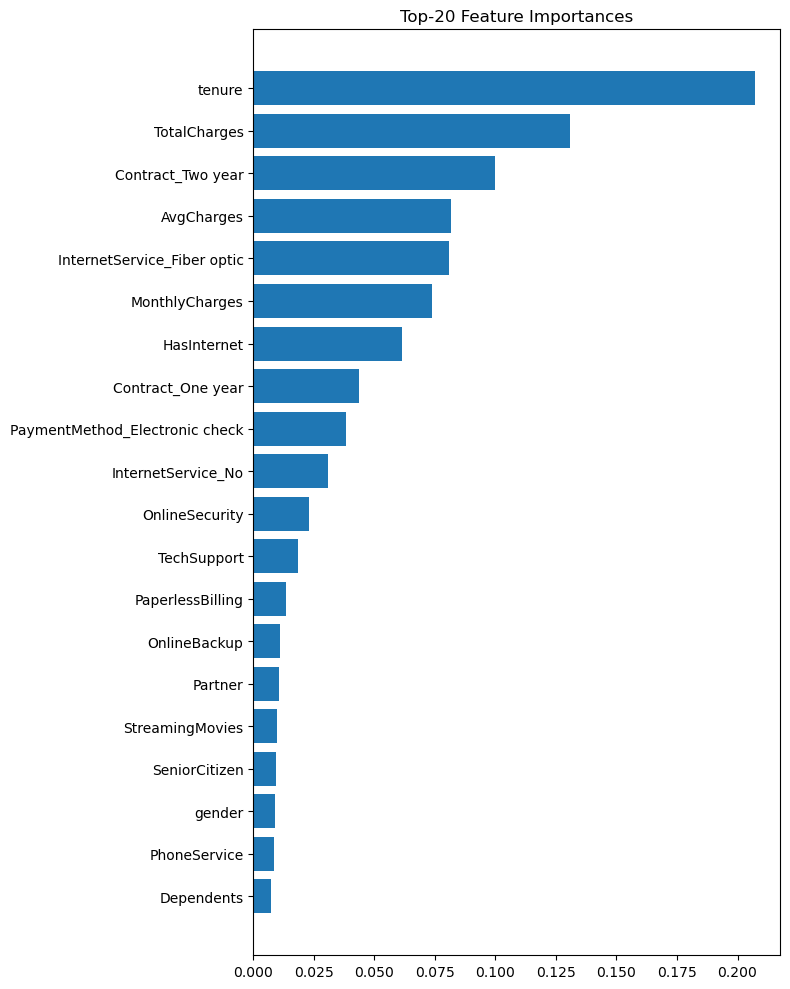

In [60]:
# ────────────────────────────────────────────────
# 랜덤포레스트 모델링 (Optuna 적용)
# ────────────────────────────────────────────────

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 500),
        "max_depth": trial.suggest_int("max_depth", 5, 20),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 10),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 5),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2"]),
        "class_weight": trial.suggest_categorical("class_weight", ["balanced", "balanced_subsample"]),
        "random_state": 42,
        "n_jobs": -1
    }

    model = RandomForestClassifier(**params)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    return scores.mean()

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=30, show_progress_bar=True)

# ────────────────────────────────────────────────
# 모델 학습
# ────────────────────────────────────────────────
best_params = study.best_trial.params
best_params["random_state"] = 42
best_params["n_jobs"] = -1

rf_optuna = RandomForestClassifier(**best_params)
rf_optuna.fit(X_train, y_train)

y_pred = rf_optuna.predict(X_test)
y_prob = rf_optuna.predict_proba(X_test)[:, 1]

# ────────────────────────────────────────────────
# 성능지표
# ────────────────────────────────────────────────
rf_optuna_acc  = accuracy_score(y_test, y_pred)
rf_optuna_prec = precision_score(y_test, y_pred, zero_division=0)
rf_optuna_rec  = recall_score(y_test, y_pred)
rf_optuna_f1   = f1_score(y_test, y_pred)
rf_optuna_auc  = roc_auc_score(y_test, y_prob)

print(f"✅ Best Params: {study.best_trial.params}")
print(f"Accuracy : {rf_optuna_acc:.4f}")
print(f"Precision: {rf_optuna_prec:.4f}")
print(f"Recall   : {rf_optuna_rec:.4f}")
print(f"F1-score : {rf_optuna_f1:.4f}")
print(f"ROC AUC  : {rf_optuna_auc:.4f}")

# ────────────────────────────────────────────────
# 혼동 행렬
# ────────────────────────────────────────────────
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Stay", "Churn"]).plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

# ────────────────────────────────────────────────
# 5-fold CV (AUC)
# ────────────────────────────────────────────────
#cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) 3번에서 사용한 cv 사용.
cv_auc = cross_val_score(rf_clf, X, y, cv=cv, scoring="roc_auc", n_jobs=-1)
print(f"\n5-fold CV AUC: {cv_auc.mean():.4f} ± {cv_auc.std():.4f}")

# ────────────────────────────────────────────────
# 피처 중요도 시각화
# ────────────────────────────────────────────────
importances = rf_clf.feature_importances_
indices = np.argsort(importances)[::-1][:20]
features = X.columns[indices]

plt.figure(figsize=(8, 10))
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), features)
plt.gca().invert_yaxis()
plt.title("Top-20 Feature Importances")
plt.tight_layout()
plt.show()


#XGBoost 코드

Fitting 5 folds for each of 256 candidates, totalling 1280 fits
✅ Best Params: {'colsample_bytree': 1, 'gamma': 1, 'learning_rate': 0.01, 'max_depth': 6, 'n_estimators': 300, 'reg_alpha': 0.1, 'reg_lambda': 2, 'subsample': 0.8}
Accuracy : 0.7580
Precision: 0.7520
Recall   : 0.7701
F1-score : 0.7609
ROC AUC  : 0.8490


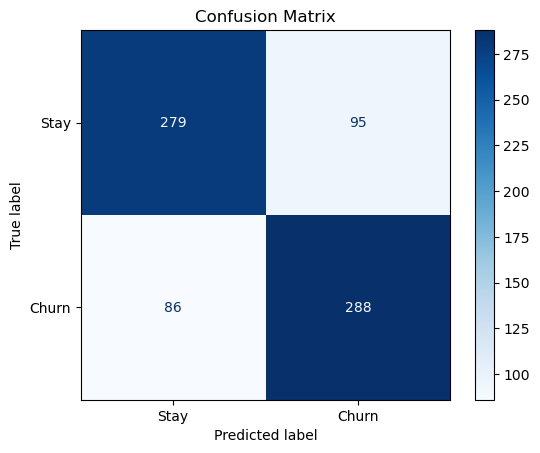


5-fold CV AUC: 0.8370 ± 0.0179


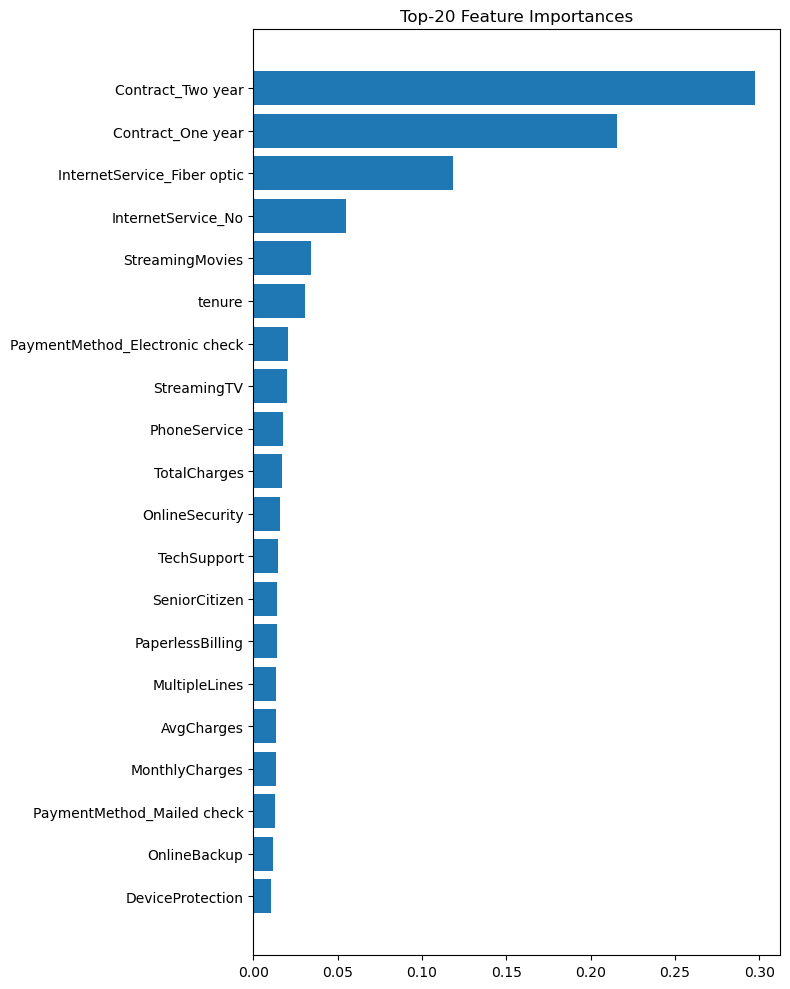

In [36]:
# ────────────────────────────────────────────────
# XGBoost 모델링 (그리드서치 적용)
# ────────────────────────────────────────────────

hyper_params = {
    'n_estimators': [100, 300],
    'max_depth': [6, 8],
    'learning_rate': [0.01, 0.1],
    'subsample': [0.8, 1],
    'colsample_bytree': [0.8, 1],
    'gamma': [0, 1],
    'reg_alpha': [0, 0.1],
    'reg_lambda': [1, 2]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

xgb_clf = xgb.XGBClassifier(use_label_encoder=False, eval_metric="logloss", random_state=42, n_jobs=-1)

xgb_grid_search = GridSearchCV(
    xgb_clf,
    param_grid=hyper_params,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=1
)
# ────────────────────────────────────────────────
# 모델 학습
# ────────────────────────────────────────────────
xgb_grid_search.fit(X_train, y_train)
xgb_best = xgb_grid_search.best_estimator_
y_pred = xgb_best.predict(X_test)
y_prob = xgb_best.predict_proba(X_test)[:, 1]
# ────────────────────────────────────────────────
# 성능지표
# ────────────────────────────────────────────────
xgb_grid_acc  = accuracy_score(y_test, y_pred)
xgb_grid_prec = precision_score(y_test, y_pred, zero_division=0)
xgb_grid_rec  = recall_score(y_test, y_pred)
xgb_grid_f1   = f1_score(y_test, y_pred)
xgb_grid_auc  = roc_auc_score(y_test, y_prob)

print(f"✅ Best Params: {xgb_grid_search.best_params_}")
print(f"Accuracy : {xgb_grid_acc:.4f}")
print(f"Precision: {xgb_grid_prec:.4f}")
print(f"Recall   : {xgb_grid_rec:.4f}")
print(f"F1-score : {xgb_grid_f1:.4f}")
print(f"ROC AUC  : {xgb_grid_auc:.4f}")
# ────────────────────────────────────────────────
# 혼동 행렬
# ────────────────────────────────────────────────
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Stay", "Churn"]).plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

# ────────────────────────────────────────────────
# 5-fold CV (AUC)
# ────────────────────────────────────────────────
cv_auc = cross_val_score(xgb_best, X, y, cv=cv, scoring="roc_auc", n_jobs=-1)
print(f"\n5-fold CV AUC: {cv_auc.mean():.4f} ± {cv_auc.std():.4f}")

# ────────────────────────────────────────────────
# 피처 중요도 시각화
# ────────────────────────────────────────────────
importances = xgb_best.feature_importances_
indices = np.argsort(importances)[::-1][:20]
features = X.columns[indices]

plt.figure(figsize=(8, 10))
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), features)
plt.gca().invert_yaxis()
plt.title("Top-20 Feature Importances")
plt.tight_layout()
plt.show()


[I 2025-05-30 18:08:09,923] A new study created in memory with name: no-name-49d92c1c-50a2-4ae3-84aa-a17829d5b18e


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2025-05-30 18:08:10,003] Trial 0 finished with value: 0.8405901499983222 and parameters: {'n_estimators': 102, 'max_depth': 8, 'learning_rate': 0.027128060532140154, 'subsample': 0.9406902987589326, 'colsample_bytree': 0.969929864259036, 'gamma': 4.446786472512491, 'reg_alpha': 0.957873681676218, 'reg_lambda': 1.5934364170439903}. Best is trial 0 with value: 0.8405901499983222.
[I 2025-05-30 18:08:10,289] Trial 1 finished with value: 0.8364134629366562 and parameters: {'n_estimators': 383, 'max_depth': 6, 'learning_rate': 0.015423738963545654, 'subsample': 0.9459992333864323, 'colsample_bytree': 0.9821043951289613, 'gamma': 0.5347497891641861, 'reg_alpha': 0.4147907507658908, 'reg_lambda': 1.9655760690512025}. Best is trial 0 with value: 0.8405901499983222.
[I 2025-05-30 18:08:10,408] Trial 2 finished with value: 0.8411785103074909 and parameters: {'n_estimators': 235, 'max_depth': 10, 'learning_rate': 0.011331933007002732, 'subsample': 0.7403034823752856, 'colsample_bytree': 0.6026

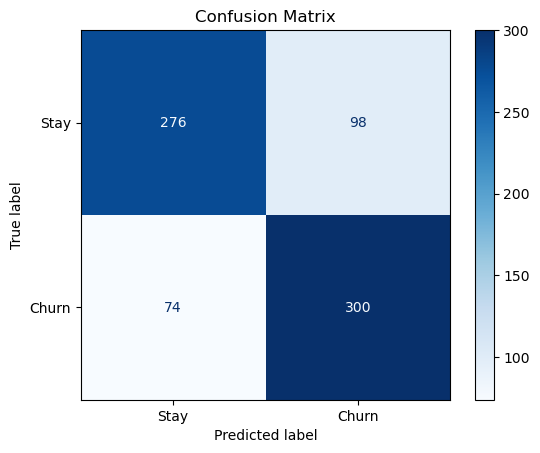


5-fold CV AUC: 0.8427 ± 0.0147


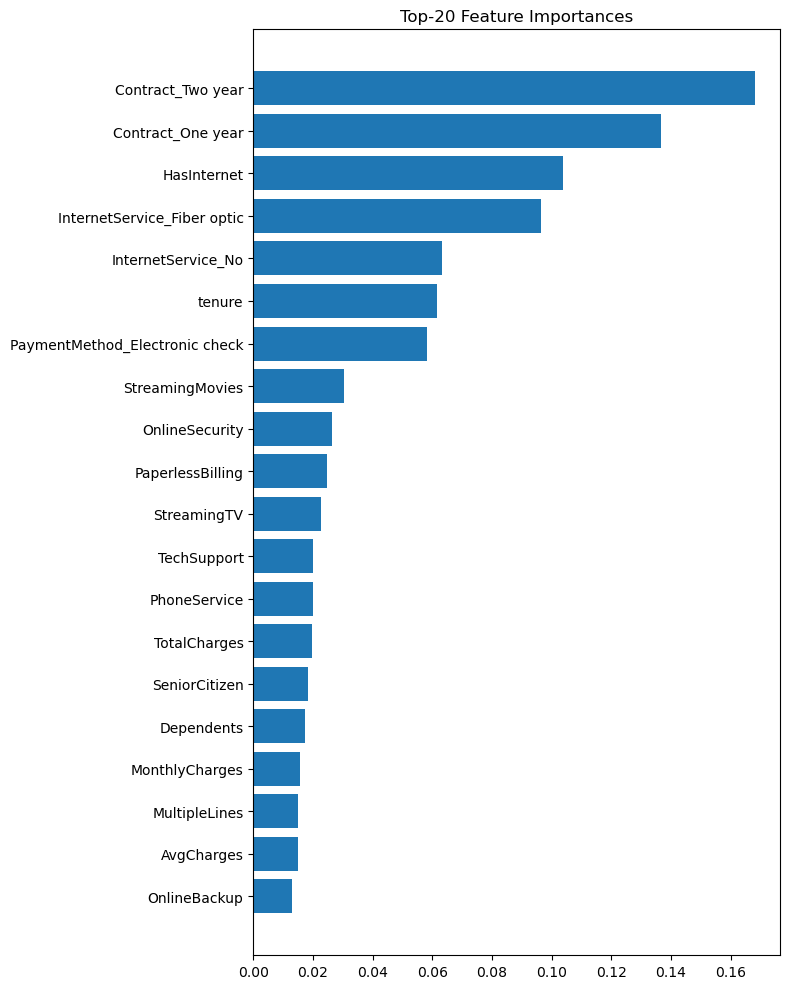

In [37]:
# ────────────────────────────────────────────────
# XGBoost 모델링 (Optuna 적용)
# ────────────────────────────────────────────────

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'gamma': trial.suggest_float('gamma', 0, 5),
        'reg_alpha': trial.suggest_float('reg_alpha', 0, 1),
        'reg_lambda': trial.suggest_float('reg_lambda', 1, 3),
        'use_label_encoder': False,
        'eval_metric': 'logloss',
        'random_state': 42,
        'n_jobs': -1
    }

    model = xgb.XGBClassifier(**params)
    score = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    return score.mean()

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30, show_progress_bar=True)

best_params = study.best_trial.params
# 추가 하이퍼파라미터는 따로 설정
best_params.update({
    'use_label_encoder': False,
    'eval_metric': 'logloss',
    'random_state': 42,
    'n_jobs': -1
})
# ────────────────────────────────────────────────
# 모델 학습
# ────────────────────────────────────────────────
xgb_best = xgb.XGBClassifier(**best_params)
xgb_best.fit(X_train, y_train)

y_pred = xgb_best.predict(X_test)
y_prob = xgb_best.predict_proba(X_test)[:, 1]

# ────────────────────────────────────────────────
# 성능지표
# ────────────────────────────────────────────────
xgb_optuna_acc  = accuracy_score(y_test, y_pred)
xgb_optuna_prec = precision_score(y_test, y_pred, zero_division=0)
xgb_optuna_rec  = recall_score(y_test, y_pred)
xgb_optuna_f1   = f1_score(y_test, y_pred)
xgb_optuna_auc  = roc_auc_score(y_test, y_prob)

print(f"✅ Best Params: {best_params}")
print(f"Accuracy : {xgb_optuna_acc:.4f}")
print(f"Precision: {xgb_optuna_prec:.4f}")
print(f"Recall   : {xgb_optuna_rec:.4f}")
print(f"F1-score : {xgb_optuna_f1:.4f}")
print(f"ROC AUC  : {xgb_optuna_auc:.4f}")

# ────────────────────────────────────────────────
# 혼동 행렬
# ────────────────────────────────────────────────
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Stay", "Churn"]).plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

# ────────────────────────────────────────────────
# 5-fold CV (AUC)
# ────────────────────────────────────────────────
cv_auc = cross_val_score(xgb_best, X, y, cv=cv, scoring="roc_auc", n_jobs=-1)
print(f"\n5-fold CV AUC: {cv_auc.mean():.4f} ± {cv_auc.std():.4f}")

# ────────────────────────────────────────────────
# 피처 중요도 시각화
# ────────────────────────────────────────────────
importances = xgb_best.feature_importances_
indices = np.argsort(importances)[::-1][:20]
features = X.columns[indices]

plt.figure(figsize=(8, 10))
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), features)
plt.gca().invert_yaxis()
plt.title("Top-20 Feature Importances")
plt.tight_layout()
plt.show()


#LogisticRegression 코드

Fitting 5 folds for each of 20 candidates, totalling 100 fits
✅ Best Params: {'C': 100, 'class_weight': 'balanced', 'max_iter': 100, 'penalty': 'l2', 'solver': 'lbfgs'}
Accuracy : 0.7741
Precision: 0.7582
Recall   : 0.8048
F1-score : 0.7808
ROC AUC  : 0.8642


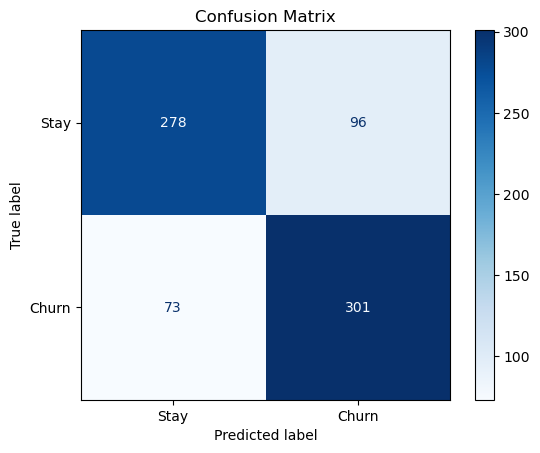


5-fold CV AUC: 0.8407 ± 0.0129


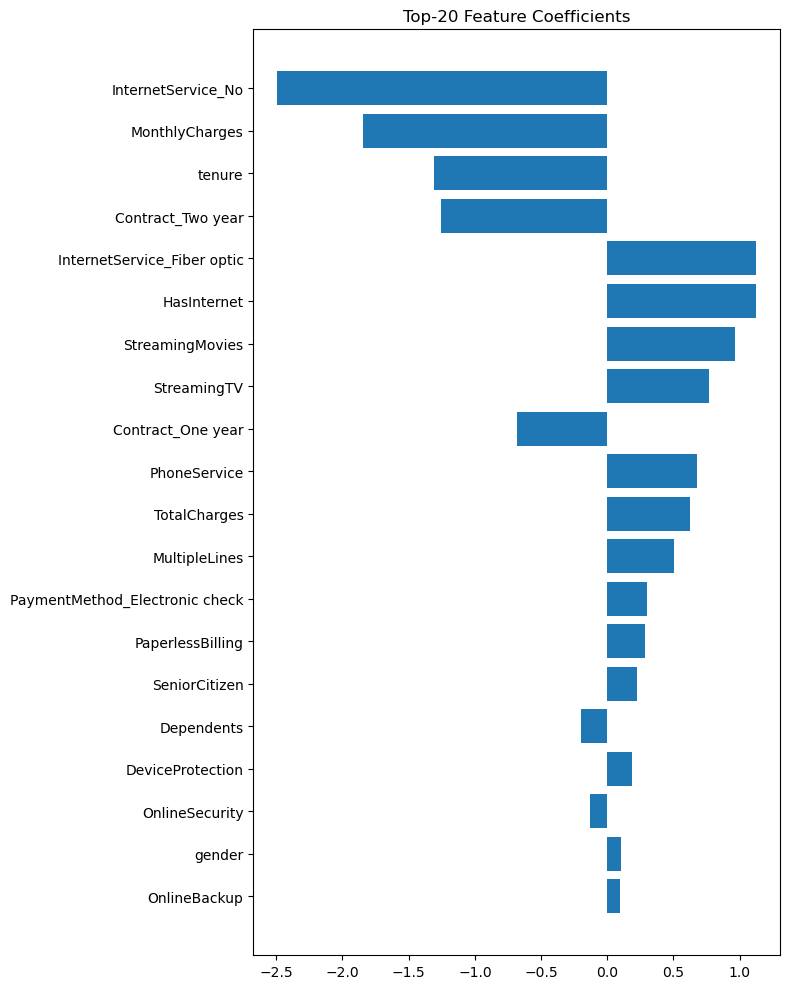

In [45]:
# ────────────────────────────────────────────────
# 로지스틱회귀 모델링 (그리드서치 적용)
# ────────────────────────────────────────────────
hyper_params = {
    'penalty': ['l2'],
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs'],
    'class_weight': ['balanced', None],
    'max_iter': [100, 200]
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

logreg = LogisticRegression(random_state=42, n_jobs=-1)

grid_search = GridSearchCV(
    logreg,
    param_grid=hyper_params,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=1
)
# ────────────────────────────────────────────────
# 모델 학습
# ────────────────────────────────────────────────
grid_search.fit(X_train, y_train)
logreg_best = grid_search.best_estimator_
y_pred = logreg_best.predict(X_test)
y_prob = logreg_best.predict_proba(X_test)[:, 1]

# ────────────────────────────────────────────────
# 성능지표
# ────────────────────────────────────────────────
lr_grid_acc  = accuracy_score(y_test, y_pred)
lr_grid_prec = precision_score(y_test, y_pred, zero_division=0)
lr_grid_rec  = recall_score(y_test, y_pred)
lr_grid_f1   = f1_score(y_test, y_pred)
lr_grid_auc  = roc_auc_score(y_test, y_prob)

print(f"✅ Best Params: {grid_search.best_params_}")
print(f"Accuracy : {lr_grid_acc:.4f}")
print(f"Precision: {lr_grid_prec:.4f}")
print(f"Recall   : {lr_grid_rec:.4f}")
print(f"F1-score : {lr_grid_f1:.4f}")
print(f"ROC AUC  : {lr_grid_auc:.4f}")
# ────────────────────────────────────────────────
# 혼동 행렬
# ────────────────────────────────────────────────
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Stay", "Churn"]).plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()
# ────────────────────────────────────────────────
# 5-fold CV (AUC)
# ────────────────────────────────────────────────
cv_auc = cross_val_score(logreg_best, X, y, cv=cv, scoring="roc_auc", n_jobs=-1)
print(f"\n5-fold CV AUC: {cv_auc.mean():.4f} ± {cv_auc.std():.4f}")

# ────────────────────────────────────────────────
# 피처 중요도 시각화 (계수 시각화)
# ────────────────────────────────────────────────
coef = logreg_best.coef_[0]
indices = np.argsort(np.abs(coef))[::-1][:20]
features = X.columns[indices]

plt.figure(figsize=(8, 10))
plt.barh(range(len(indices)), coef[indices], align='center')
plt.yticks(range(len(indices)), features)
plt.gca().invert_yaxis()
plt.title("Top-20 Feature Coefficients")
plt.tight_layout()
plt.show()


[I 2025-06-02 14:01:12,831] A new study created in memory with name: no-name-3a8a1a79-39a6-4dc6-9b40-f01cab3e670b


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2025-06-02 14:01:13,787] Trial 0 finished with value: 0.8376170288922943 and parameters: {'C': 84.17109279522906, 'class_weight': None, 'max_iter': 103}. Best is trial 0 with value: 0.8376170288922943.
[I 2025-06-02 14:01:14,394] Trial 1 finished with value: 0.8374693795371415 and parameters: {'C': 11.130487927180923, 'class_weight': 'balanced', 'max_iter': 112}. Best is trial 0 with value: 0.8376170288922943.
[I 2025-06-02 14:01:15,000] Trial 2 finished with value: 0.8374470084227246 and parameters: {'C': 0.6085261870243137, 'class_weight': 'balanced', 'max_iter': 209}. Best is trial 0 with value: 0.8376170288922943.
[I 2025-06-02 14:01:15,575] Trial 3 finished with value: 0.8284605317613897 and parameters: {'C': 0.003096093384870939, 'class_weight': 'balanced', 'max_iter': 158}. Best is trial 0 with value: 0.8376170288922943.
[I 2025-06-02 14:01:15,610] Trial 4 finished with value: 0.8313665395241665 and parameters: {'C': 0.00836306590922022, 'class_weight': None, 'max_iter': 237}

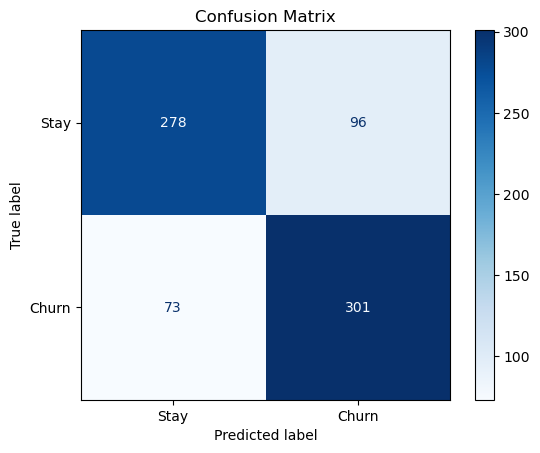


5-fold CV AUC: 0.8408 ± 0.0129


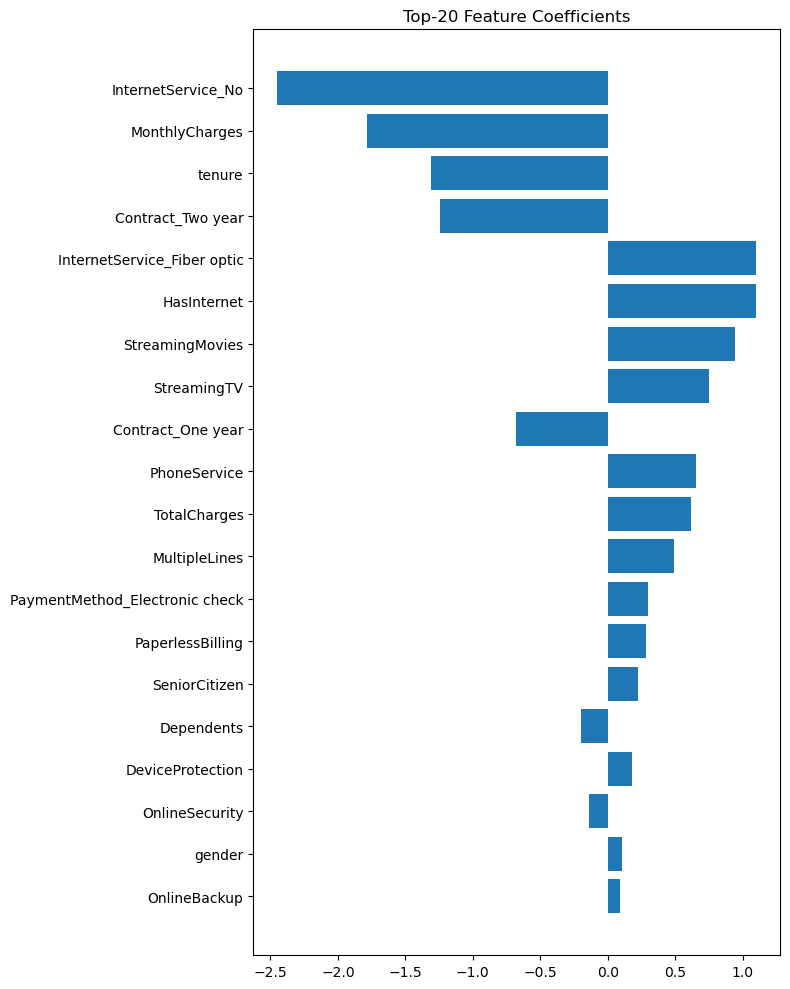

In [18]:
# ────────────────────────────────────────────────
# 로지스틱 회귀 모델링 (Optuna 적용)
# ────────────────────────────────────────────────

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def objective(trial):
    C = trial.suggest_loguniform('C', 1e-3, 1e2)
    class_weight = trial.suggest_categorical('class_weight', ['balanced', None])
    max_iter = trial.suggest_int('max_iter', 100, 300)

    model = LogisticRegression(
        penalty='l2',
        C=C,
        solver='lbfgs',
        class_weight=class_weight,
        max_iter=max_iter,
        random_state=42,
        n_jobs=-1
    )
    score = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    return score.mean()

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30, show_progress_bar=True)

best_params = study.best_trial.params

logreg_best = LogisticRegression(
    penalty='l2',
    C=best_params['C'],
    solver='lbfgs',
    class_weight=best_params['class_weight'],
    max_iter=best_params['max_iter'],
    random_state=42,
    n_jobs=-1
)
# ────────────────────────────────────────────────
# 모델 학습
# ────────────────────────────────────────────────
logreg_best.fit(X_train, y_train)

y_pred = logreg_best.predict(X_test)
y_prob = logreg_best.predict_proba(X_test)[:, 1]

# ────────────────────────────────────────────────
# 성능지표
# ────────────────────────────────────────────────
lr_optuna_acc  = accuracy_score(y_test, y_pred)
lr_optuna_prec = precision_score(y_test, y_pred, zero_division=0)
lr_optuna_rec  = recall_score(y_test, y_pred)
lr_optuna_f1   = f1_score(y_test, y_pred)
lr_optuna_auc  = roc_auc_score(y_test, y_prob)

print(f"✅ Best Params: {best_params}")
print(f"Accuracy : {lr_optuna_acc:.4f}")
print(f"Precision: {lr_optuna_prec:.4f}")
print(f"Recall   : {lr_optuna_rec:.4f}")
print(f"F1-score : {lr_optuna_f1:.4f}")
print(f"ROC AUC  : {lr_optuna_auc:.4f}")
# ────────────────────────────────────────────────
# 혼동 행렬
# ────────────────────────────────────────────────
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Stay", "Churn"]).plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()
# ────────────────────────────────────────────────
# 5-fold CV (AUC)
# ────────────────────────────────────────────────
cv_auc = cross_val_score(logreg_best, X, y, cv=cv, scoring="roc_auc", n_jobs=-1)
print(f"\n5-fold CV AUC: {cv_auc.mean():.4f} ± {cv_auc.std():.4f}")
# ────────────────────────────────────────────────
# 피처 중요도 시각화 (계수 시각화)
# ────────────────────────────────────────────────
coef = logreg_best.coef_[0]
indices = np.argsort(np.abs(coef))[::-1][:20]
features = X.columns[indices]

plt.figure(figsize=(8, 10))
plt.barh(range(len(indices)), coef[indices], align='center')
plt.yticks(range(len(indices)), features)
plt.gca().invert_yaxis()
plt.title("Top-20 Feature Coefficients")
plt.tight_layout()
plt.show()

#LightGBM 코드

Fitting 5 folds for each of 32 candidates, totalling 160 fits
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 1495, number of negative: 1495
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000687 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 880
[LightGBM] [Info] Number of data points in the train set: 2990, number of used features: 25
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with posi

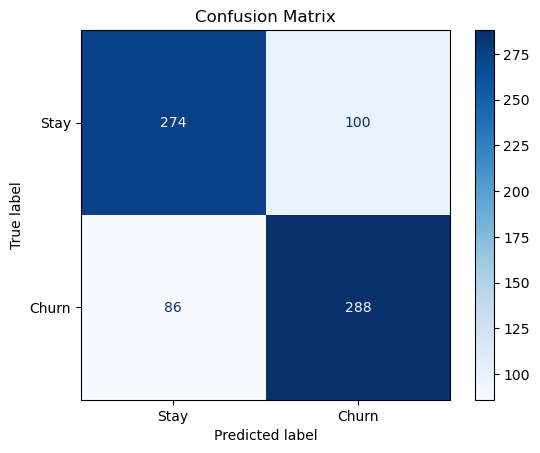

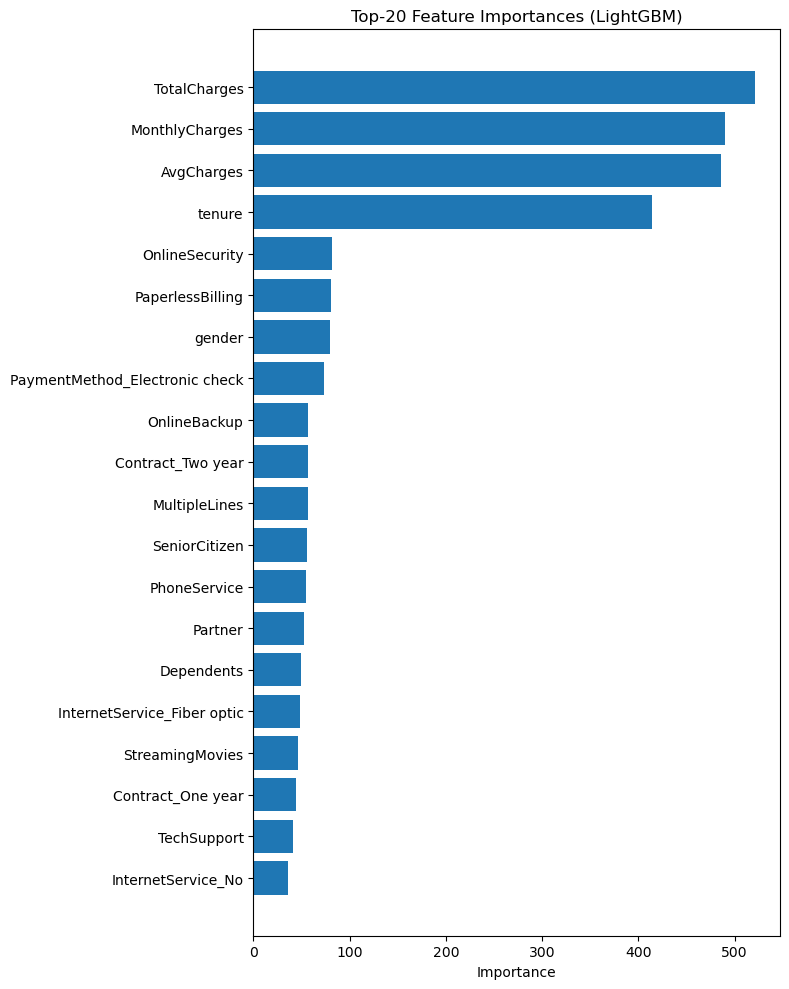

In [49]:
# ────────────────────────────────────────────────
# LightGBM 모델링 (그리드서치 적용)
# ────────────────────────────────────────────────

param_grid = {
    'n_estimators': [100, 300],
    'max_depth': [8, 10],
    'num_leaves': [31, 50],
    'learning_rate': [0.05, 0.1],
    'min_child_samples': [20, 30],
    'class_weight': ['balanced']
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lgbm = lgb.LGBMClassifier(random_state=42, n_jobs=-1)
grid_search = GridSearchCV(
    estimator=lgbm,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# ────────────────────────────────────────────────
# 모델 학습
# ────────────────────────────────────────────────
grid_search.fit(X_train, y_train)
best_lgbm = grid_search.best_estimator_
y_pred = best_lgbm.predict(X_test)
y_prob = best_lgbm.predict_proba(X_test)[:, 1]

# ────────────────────────────────────────────────
# 성능지표
# ────────────────────────────────────────────────
lgb_grid_acc  = accuracy_score(y_test, y_pred)
lgb_grid_prec = precision_score(y_test, y_pred, zero_division=0)
lgb_grid_rec  = recall_score(y_test, y_pred)
lgb_grid_f1   = f1_score(y_test, y_pred)
lgb_grid_auc  = roc_auc_score(y_test, y_prob)

print(f"✅ Best Params: {grid_search.best_params_}")
print(f"Accuracy : {lgb_grid_acc:.4f}")
print(f"Precision: {lgb_grid_prec:.4f}")
print(f"Recall   : {lgb_grid_rec:.4f}")
print(f"F1-score : {lgb_grid_f1:.4f}")
print(f"ROC AUC  : {lgb_grid_auc:.4f}")
# ────────────────────────────────────────────────
# 혼동 행렬
# ────────────────────────────────────────────────
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Stay", "Churn"]).plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

# ────────────────────────────────────────────────
# 피처 중요도 시각화
# ────────────────────────────────────────────────
importances = best_lgbm.feature_importances_
indices = np.argsort(importances)[::-1][:20]
features = X.columns[indices]
plt.figure(figsize=(8, 10))
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), features)
plt.gca().invert_yaxis()
plt.title("Top-20 Feature Importances (LightGBM)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

[I 2025-05-30 18:13:50,360] A new study created in memory with name: no-name-08cc0e30-fdb8-48d4-971c-9085343d01a3


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2025-05-30 18:13:51,752] Trial 0 finished with value: 0.8023221216764913 and parameters: {'n_estimators': 231, 'max_depth': 18, 'num_leaves': 59, 'min_child_samples': 34, 'subsample': 0.7885908302478025, 'colsample_bytree': 0.937589159974949, 'learning_rate': 0.20558953888730572, 'class_weight': None}. Best is trial 0 with value: 0.8023221216764913.
[I 2025-05-30 18:13:52,593] Trial 1 finished with value: 0.8055950157157078 and parameters: {'n_estimators': 233, 'max_depth': 20, 'num_leaves': 26, 'min_child_samples': 34, 'subsample': 0.6165641203412807, 'colsample_bytree': 0.9519075788131915, 'learning_rate': 0.18232728160028533, 'class_weight': 'balanced'}. Best is trial 1 with value: 0.8055950157157078.
[I 2025-05-30 18:13:53,657] Trial 2 finished with value: 0.8025972863838211 and parameters: {'n_estimators': 297, 'max_depth': 13, 'num_leaves': 89, 'min_child_samples': 36, 'subsample': 0.9753186481508465, 'colsample_bytree': 0.9451531500451382, 'learning_rate': 0.188126832916007, 

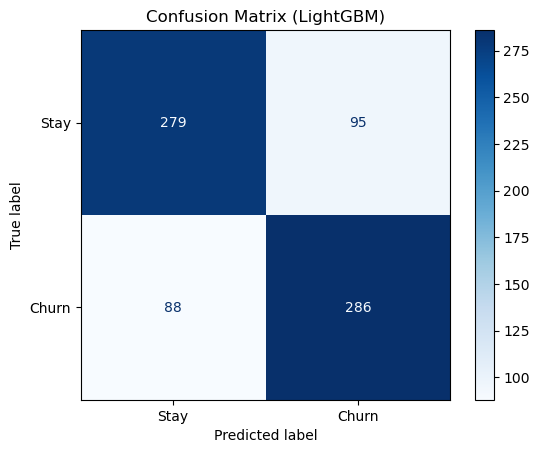


5-fold CV AUC (LightGBM): 0.8343 ± 0.0182


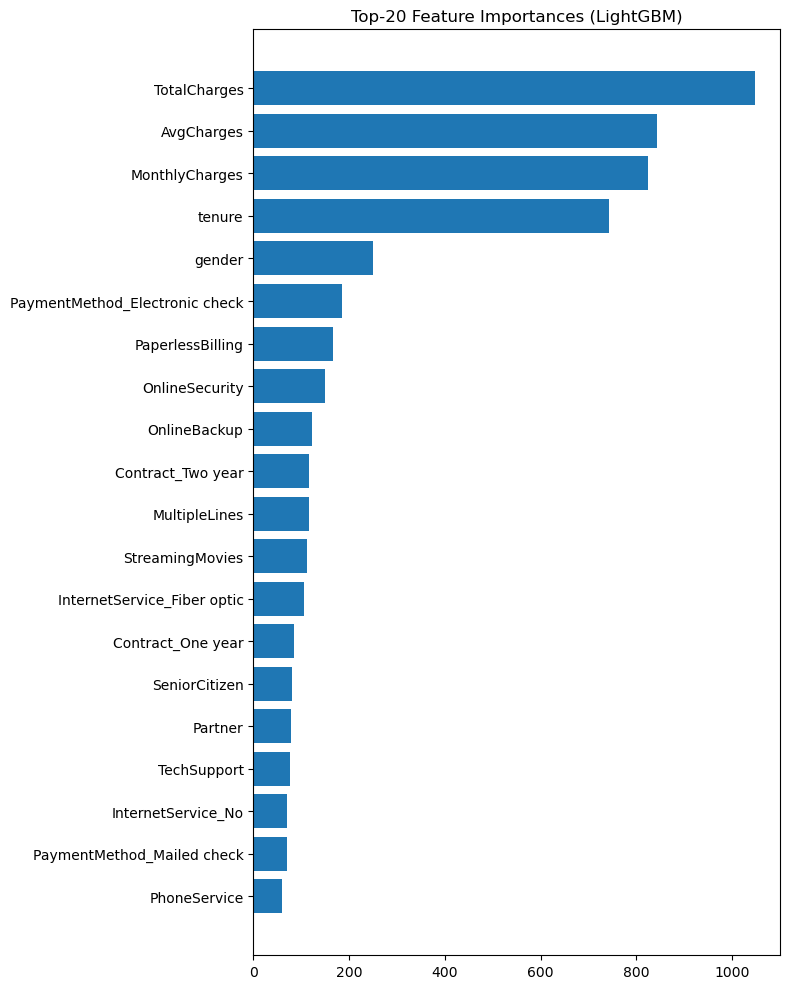

In [50]:
# ────────────────────────────────────────────────
# LightGBM 모델링 (Optuna 적용)
# ────────────────────────────────────────────────
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def objective_lgb(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 500),
        "max_depth": trial.suggest_int("max_depth", 5, 20),
        "num_leaves": trial.suggest_int("num_leaves", 20, 150),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 50),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3),
        "class_weight": trial.suggest_categorical("class_weight", ["balanced", None]),
        "random_state": 42,
        "n_jobs": -1
    }

    model = lgb.LGBMClassifier(**params)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    return scores.mean()

study_lgb = optuna.create_study(direction="maximize")
study_lgb.optimize(objective_lgb, n_trials=30, show_progress_bar=True)

# ────────────────────────────────────────────────
# 모델 학습
# ────────────────────────────────────────────────
best_params_lgb = study_lgb.best_trial.params
best_params_lgb["random_state"] = 42
best_params_lgb["n_jobs"] = -1

lgb_optuna = lgb.LGBMClassifier(**best_params_lgb)
lgb_optuna.fit(X_train, y_train)

y_pred_lgb = lgb_optuna.predict(X_test)
y_prob_lgb = lgb_optuna.predict_proba(X_test)[:, 1]

# ────────────────────────────────────────────────
# 성능지표
# ────────────────────────────────────────────────
lgb_optuna_acc  = accuracy_score(y_test, y_pred_lgb)
lgb_optuna_prec = precision_score(y_test, y_pred_lgb, zero_division=0)
lgb_optuna_rec  = recall_score(y_test, y_pred_lgb)
lgb_optuna_f1   = f1_score(y_test, y_pred_lgb)
lgb_optuna_auc  = roc_auc_score(y_test, y_prob_lgb)

print(f"✅ Best Params (LightGBM): {study_lgb.best_trial.params}")
print(f"Accuracy : {lgb_optuna_acc:.4f}")
print(f"Precision: {lgb_optuna_prec:.4f}")
print(f"Recall   : {lgb_optuna_rec:.4f}")
print(f"F1-score : {lgb_optuna_f1:.4f}")
print(f"ROC AUC  : {lgb_optuna_auc:.4f}")

# ────────────────────────────────────────────────
# 혼동 행렬
# ────────────────────────────────────────────────
cm_lgb = confusion_matrix(y_test, y_pred_lgb)
ConfusionMatrixDisplay(cm_lgb, display_labels=["Stay", "Churn"]).plot(cmap="Blues")
plt.title("Confusion Matrix (LightGBM)")
plt.show()

# ────────────────────────────────────────────────
# 5-fold CV (AUC)
# ────────────────────────────────────────────────
cv_auc_lgb = cross_val_score(lgb_optuna, X, y, cv=cv, scoring="roc_auc", n_jobs=-1)
print(f"\n5-fold CV AUC (LightGBM): {cv_auc_lgb.mean():.4f} ± {cv_auc_lgb.std():.4f}")

# ────────────────────────────────────────────────
# 피처 중요도 시각화
# ────────────────────────────────────────────────
importances_lgb = lgb_optuna.feature_importances_
indices_lgb = np.argsort(importances_lgb)[::-1][:20]
features_lgb = X.columns[indices_lgb]

plt.figure(figsize=(8, 10))
plt.barh(range(len(indices_lgb)), importances_lgb[indices_lgb], align='center')
plt.yticks(range(len(indices_lgb)), features_lgb)
plt.gca().invert_yaxis()
plt.title("Top-20 Feature Importances (LightGBM)")
plt.tight_layout()
plt.show()


#정리

In [52]:
model_results = pd.DataFrame({
    "Model": [
        "RandomForest (Optuna)", "RandomForest (GridSearch)",
        "LightGBM (Optuna)", "LightGBM (GridSearch)",
        "XGBoost (Optuna)", "XGBoost (GridSearch)",
        "LogisticRegression (Optuna)", "LogisticRegression (GridSearch)"
    ],
    "Accuracy": [
        rf_optuna_acc, rf_grid_acc,
        lgb_optuna_acc, lgb_grid_acc,
        xgb_optuna_acc, xgb_grid_acc,
        lr_optuna_acc, lr_grid_acc
    ],
    "Precision": [
        rf_optuna_prec, rf_grid_prec,
        lgb_optuna_prec, lgb_grid_prec,
        xgb_optuna_prec, xgb_grid_prec,
        lr_optuna_prec, lr_grid_prec
    ],
    "Recall": [
        rf_optuna_rec, rf_grid_rec,
        lgb_optuna_rec, lgb_grid_rec,
        xgb_optuna_rec, xgb_grid_rec,
        lr_optuna_rec, lr_grid_rec
    ],
    "F1-score": [
        rf_optuna_f1, rf_grid_f1,
        lgb_optuna_f1, lgb_grid_f1,
        xgb_optuna_f1, xgb_grid_f1,
        lr_optuna_f1, lr_grid_f1
    ],
    "ROC AUC": [
        rf_optuna_auc, rf_grid_auc,
        lgb_optuna_auc, lgb_grid_auc,
        xgb_optuna_auc, xgb_grid_auc,
        lr_optuna_auc, lr_grid_auc
    ]
})
model_results = model_results.sort_values(by="Accuracy", ascending=False).reset_index(drop=True)

print(model_results)


                             Model  Accuracy  Precision    Recall  F1-score  \
0      LogisticRegression (Optuna)  0.774064   0.758186  0.804813  0.780804   
1  LogisticRegression (GridSearch)  0.774064   0.758186  0.804813  0.780804   
2                 XGBoost (Optuna)  0.770053   0.753769  0.802139  0.777202   
3        RandomForest (GridSearch)  0.762032   0.752577  0.780749  0.766404   
4             XGBoost (GridSearch)  0.758021   0.751958  0.770053  0.760898   
5                LightGBM (Optuna)  0.755348   0.750656  0.764706  0.757616   
6            RandomForest (Optuna)  0.754011   0.742347  0.778075  0.759791   
7            LightGBM (GridSearch)  0.751337   0.742268  0.770053  0.755906   

    ROC AUC  
0  0.864158  
1  0.864173  
2  0.854185  
3  0.845456  
4  0.848981  
5  0.843536  
6  0.844852  
7  0.835937  


# 이익 관점을 고려한 버전

[I 2025-06-02 14:34:38,627] A new study created in memory with name: no-name-e400039f-680c-44ff-bdad-f213e08ed074


  0%|          | 0/100 [00:00<?, ?it/s]

[I 2025-06-02 14:34:43,152] Trial 0 finished with value: -0.8373038332904553 and parameters: {'C': 0.29301511056499235, 'class_weight': 'balanced', 'max_iter': 263}. Best is trial 0 with value: -0.8373038332904553.
[I 2025-06-02 14:34:43,797] Trial 1 finished with value: -0.8375678124405768 and parameters: {'C': 7.355571720478102, 'class_weight': 'balanced', 'max_iter': 110}. Best is trial 1 with value: -0.8375678124405768.
[I 2025-06-02 14:34:44,412] Trial 2 finished with value: -0.8375700495520185 and parameters: {'C': 2.7269621374197706, 'class_weight': None, 'max_iter': 191}. Best is trial 2 with value: -0.8375700495520185.
[I 2025-06-02 14:34:44,989] Trial 3 finished with value: -0.8373821321909152 and parameters: {'C': 14.30948519353629, 'class_weight': 'balanced', 'max_iter': 151}. Best is trial 2 with value: -0.8375700495520185.
[I 2025-06-02 14:34:45,024] Trial 4 finished with value: -0.8373843693023568 and parameters: {'C': 1.8769336808633532, 'class_weight': None, 'max_iter'

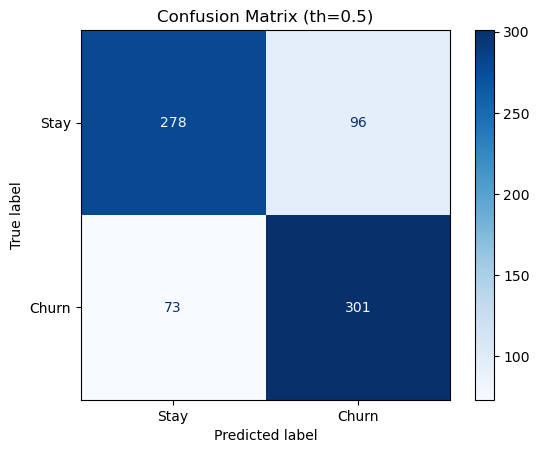

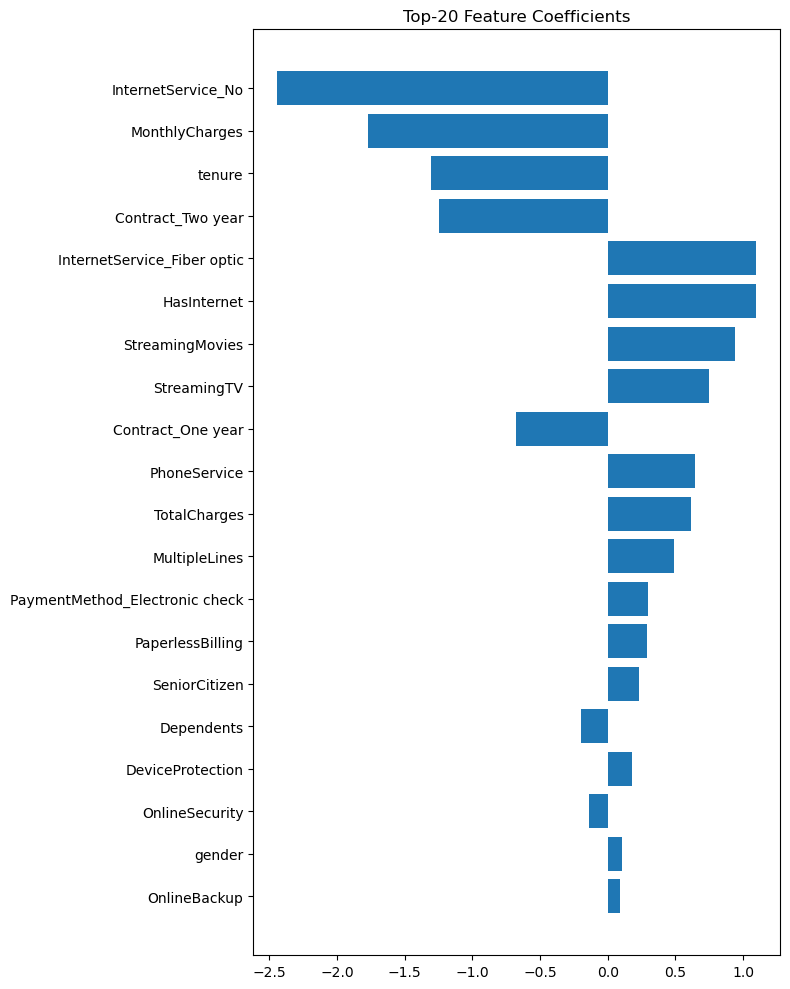

In [30]:
#─────────────────────────────────────────────────────────
# 라이브러리 & 공통 세팅
#─────────────────────────────────────────────────────────
import numpy as np, optuna, matplotlib.pyplot as plt, warnings
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay
)
warnings.filterwarnings("ignore")

#─────────────────────────────────────────────────────────
# 1. 증분(Incremental) 손익 함수
#   - ‘캠페인 전혀 안 함’을 0원으로 두고,
#     캠페인을 했을 때 절감·추가 비용만 계산
#─────────────────────────────────────────────────────────
def profit_incremental(cm,
                       V=240_000, C_ret=15_000, C_false=15_000,
                       L_miss=240_000, p_succ=0.30):
    """
    ΔProfit = (전략 손익) − (아무 것도 안 했을 때 손익)
    → 아무것도 안 하면 0원이 기준
    """
    tn, fp, fn, tp = cm.ravel()

    # TP : 캠페인 비용(-C_ret) + 성공 시 LTV/L_miss 절감
    delta_tp = tp * (-C_ret + p_succ * (L_miss + V))

    # FP : 불필요 캠페인 비용
    delta_fp = fp * (-C_false)

    # FN, TN : baseline과 동일 → 증분 0
    return delta_tp + delta_fp

#─────────────────────────────────────────────────────────
# 2. Optuna – ROC-AUC 기준 하이퍼파라미터 최적화
#─────────────────────────────────────────────────────────
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def objective(trial):
    C            = trial.suggest_float('C', 1e-3, 1e2, log=True)
    class_weight = trial.suggest_categorical('class_weight', ['balanced', None])
    max_iter     = trial.suggest_int('max_iter', 100, 300)

    model = LogisticRegression(
        penalty='l2',
        C=C,
        solver='lbfgs',
        class_weight=class_weight,
        max_iter=max_iter,
        random_state=42,
        n_jobs=-1
    )
    auc = cross_val_score(model, X_train, y_train, cv=cv,
                          scoring='roc_auc', n_jobs=-1).mean()
    return auc * -1                       # minimize

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=100, show_progress_bar=True)

best_params = study.best_trial.params
print("◎ Best params :", best_params)

#─────────────────────────────────────────────────────────
# 3. 모델 학습 & 기본(0.5) cut-off 손익 계산
#─────────────────────────────────────────────────────────
logreg_best = LogisticRegression(
    penalty='l2',
    C=best_params['C'],
    solver='lbfgs',
    class_weight=best_params['class_weight'],
    max_iter=best_params['max_iter'],
    random_state=42,
    n_jobs=-1
).fit(X_train, y_train)

y_prob = logreg_best.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)           # ← 별도 임계값 설정 없이 0.5 그대로
cm      = confusion_matrix(y_test, y_pred)

#–– 일반 지표
print("\n【일반 지표 – th=0.5】")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_prob):.4f}")

#–– 증분 손익 (baseline = 아무것도 안 함)
inc_profit = profit_incremental(cm, p_succ=0.30)
print(f"\n◎ Incremental Profit vs. 'Do-Nothing' : ₩{inc_profit:,.0f}")

#─────────────────────────────────────────────────────────
# 4. 시각화 (혼동 행렬 & 상위 계수)
#─────────────────────────────────────────────────────────
ConfusionMatrixDisplay(cm, display_labels=["Stay", "Churn"]).plot(cmap="Blues")
plt.title("Confusion Matrix (th=0.5)")
plt.show()

coef     = logreg_best.coef_[0]
idx_top  = np.argsort(np.abs(coef))[::-1][:20]
features = X.columns[idx_top]

plt.figure(figsize=(8,10))
plt.barh(range(20), coef[idx_top], align='center')
plt.yticks(range(20), features)
plt.gca().invert_yaxis()
plt.title("Top-20 Feature Coefficients")
plt.tight_layout()
plt.show()


[I 2025-06-02 14:34:49,096] A new study created in memory with name: no-name-4e9a5b3f-db3b-4444-9196-984a2ff37086


  0%|          | 0/100 [00:00<?, ?it/s]

[I 2025-06-02 14:34:49,167] Trial 0 finished with value: -34483800.0 and parameters: {'C': 0.03749710181728809, 'class_weight': None, 'max_iter': 170, 'th': 0.16869886743358897}. Best is trial 0 with value: -34483800.0.
[I 2025-06-02 14:34:49,235] Trial 1 finished with value: -21906600.0 and parameters: {'C': 0.07514378357561753, 'class_weight': None, 'max_iter': 208, 'th': 0.681914572701158}. Best is trial 0 with value: -34483800.0.
[I 2025-06-02 14:34:49,302] Trial 2 finished with value: -22177200.0 and parameters: {'C': 0.08056052484609952, 'class_weight': None, 'max_iter': 168, 'th': 0.6748482774869888}. Best is trial 0 with value: -34483800.0.
[I 2025-06-02 14:34:49,370] Trial 3 finished with value: -27360000.0 and parameters: {'C': 14.527101357579337, 'class_weight': None, 'max_iter': 233, 'th': 0.5685062211628574}. Best is trial 0 with value: -34483800.0.
[I 2025-06-02 14:34:49,437] Trial 4 finished with value: -14199000.0 and parameters: {'C': 0.0011428929251844089, 'class_weig

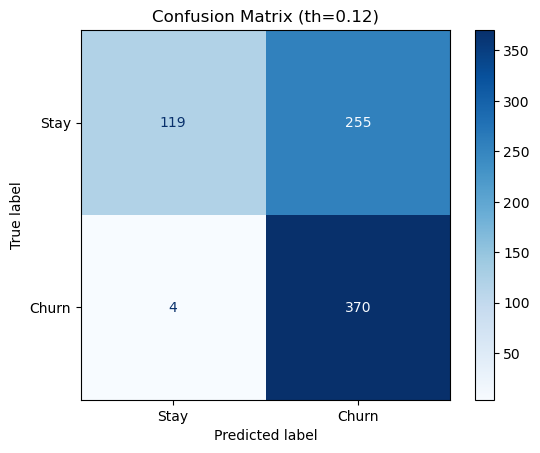

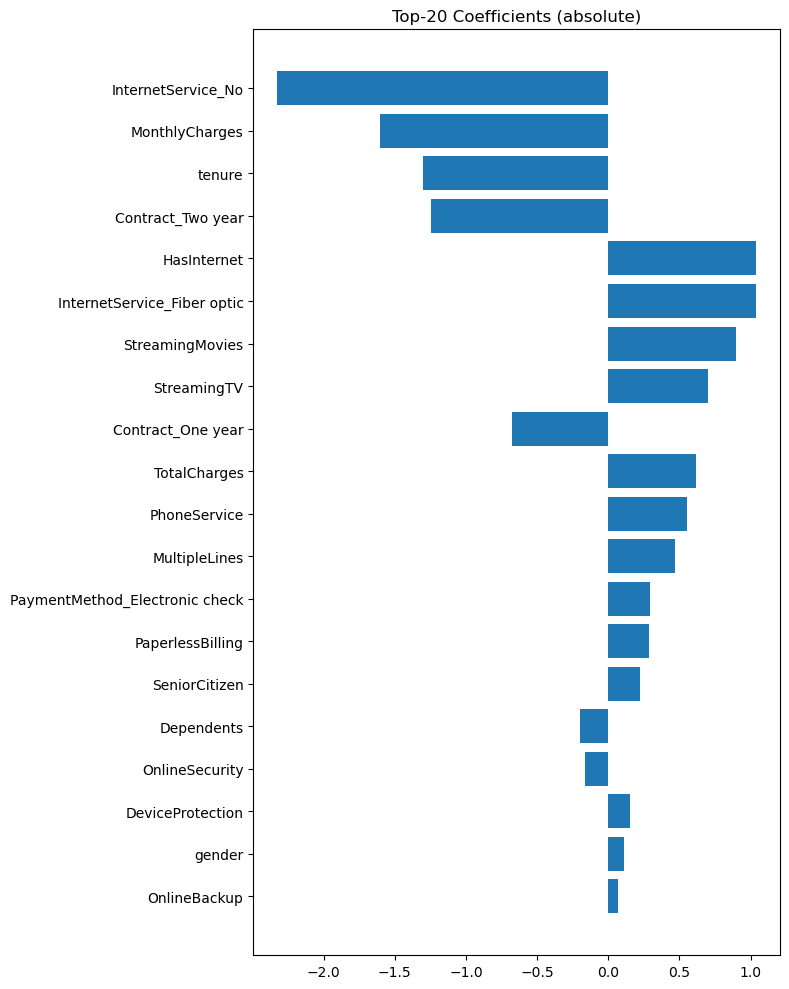

In [31]:
#─────────────────────────────────────────────────────────
# 0. 라이브러리 & 공통 세팅
#─────────────────────────────────────────────────────────
import numpy as np, optuna, matplotlib.pyplot as plt, warnings
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay
)
warnings.filterwarnings("ignore")

#─────────────────────────────────────────────────────────
# 1. 증분(Incremental) 손익 함수
#    - “캠페인 전혀 안 함”을 0원으로 둠
#─────────────────────────────────────────────────────────
def profit_incremental(cm,
                       V=240_000, C_ret=15_000, C_false=15_000,
                       L_miss=240_000, p_succ=0.30):
    """ΔProfit = 전략 손익 − (아무 것도 안 했을 때 손익)"""
    tn, fp, fn, tp = cm.ravel()
    delta_tp = tp * (-C_ret + p_succ * (L_miss + V))  # 캠페인 성공·실패 모두 포함
    delta_fp = fp * (-C_false)                        # 불필요 캠페인 비용
    return delta_tp + delta_fp                        # fn·tn은 증분 0

#─────────────────────────────────────────────────────────
# 2. Optuna – “증분 손익” 최대화를 위한 목적 함수
#─────────────────────────────────────────────────────────
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def objective(trial):
    #–– 하이퍼파라미터 & threshold 샘플링 ––#
    C            = trial.suggest_float('C', 1e-3, 1e2, log=True)
    class_weight = trial.suggest_categorical('class_weight', ['balanced', None])
    max_iter     = trial.suggest_int('max_iter', 100, 300)
    threshold    = trial.suggest_float('th', 0.1, 0.9)      # cut-off 최적화

    model = LogisticRegression(
        penalty='l2', C=C, solver='lbfgs',
        class_weight=class_weight, max_iter=max_iter,
        random_state=42, n_jobs=-1
    )

    profits = []
    for tr_idx, vl_idx in cv.split(X_train, y_train):
        X_tr, X_vl = X_train.iloc[tr_idx], X_train.iloc[vl_idx]
        y_tr, y_vl = y_train.iloc[tr_idx], y_train.iloc[vl_idx]

        model.fit(X_tr, y_tr)
        prob  = model.predict_proba(X_vl)[:, 1]
        pred  = (prob >= threshold).astype(int)
        cm    = confusion_matrix(y_vl, pred)

        profits.append(profit_incremental(cm, p_succ=0.30))   # p_succ 고정

    # Optuna는 기본이 minimize → 부호를 반전해 ‘손익 최대화’
    return -np.mean(profits)

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=100, show_progress_bar=True)

best = study.best_trial.params
print("\n◎ Best Params (ΔProfit-기준)\n", best)

#─────────────────────────────────────────────────────────
# 3. 최적 모델 학습 & 테스트 세트 평가
#─────────────────────────────────────────────────────────
logreg_best = LogisticRegression(
    penalty='l2',
    C=best['C'],
    solver='lbfgs',
    class_weight=best['class_weight'],
    max_iter=best['max_iter'],
    random_state=42,
    n_jobs=-1
).fit(X_train, y_train)

best_th = best['th']

y_prob = logreg_best.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= best_th).astype(int)
cm     = confusion_matrix(y_test, y_pred)

#–– 증분 손익
inc_profit = profit_incremental(cm, p_succ=0.30)
print(f"\n◎ Incremental Profit vs. 'Do-Nothing' : ₩{inc_profit:,.0f}")

#–– 참고용 일반 성능 지표
print("\n【일반 지표 – th={:.2f}】".format(best_th))
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_prob):.4f}")

#─────────────────────────────────────────────────────────
# 4. 시각화 – 혼동 행렬 & 계수
#─────────────────────────────────────────────────────────
ConfusionMatrixDisplay(cm, display_labels=["Stay", "Churn"]).plot(cmap="Blues")
plt.title(f"Confusion Matrix (th={best_th:.2f})")
plt.show()

coef     = logreg_best.coef_[0]
idx_top  = np.argsort(np.abs(coef))[::-1][:20]
features = X.columns[idx_top]

plt.figure(figsize=(8,10))
plt.barh(range(20), coef[idx_top], align='center')
plt.yticks(range(20), features)
plt.gca().invert_yaxis()
plt.title("Top-20 Coefficients (absolute)")
plt.tight_layout()
plt.show()
